<a href="https://colab.research.google.com/github/alijonovanargiza28/computer-vision/blob/main/menu_Detector_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms

from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
from torch.utils.data import Dataset, DataLoader
from PIL import Image, UnidentifiedImageError
from google.colab import drive, files
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch: 2.11.0+cu130
CUDA available: True


In [4]:

drive.mount('/content/drive')

DATASET_PATH = '/content/drive/MyDrive/food101_dataset'

print("Dataset exists:", os.path.isdir(DATASET_PATH))

if os.path.isdir(DATASET_PATH):
    print("Folders:", os.listdir(DATASET_PATH))
else:
    raise FileNotFoundError(DATASET_PATH)


Mounted at /content/drive
Dataset exists: True
Folders: ['cheesecake', 'pizza', 'pilaf', 'kebab', 'chocolate_cake', 'hot_dog']


In [5]:

CUSTOM_CLASS_MAPPING = {
    "cheesecake": "cheesecake",
    "pizza": "pizza",
    "pilaf": "pilaf",
    "kebab": "kebab",
    "chocolate_cake": "chocolate_cake",
    "hot_dog": "hot_dog"
}

CLASSES = [
    "cheesecake",
    "pizza",
    "pilaf",
    "kebab",
    "chocolate_cake",
    "hot_dog"
]

CLASS_TO_IDX = {
    cls: i for i, cls in enumerate(CLASSES)
}

NUM_CLASSES = len(CLASSES)

print("Classes:", CLASSES)
print("Class mapping:", CLASS_TO_IDX)
print("Number of classes:", NUM_CLASSES)


Classes: ['cheesecake', 'pizza', 'pilaf', 'kebab', 'chocolate_cake', 'hot_dog']
Class mapping: {'cheesecake': 0, 'pizza': 1, 'pilaf': 2, 'kebab': 3, 'chocolate_cake': 4, 'hot_dog': 5}
Number of classes: 6


In [6]:

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Transform created!")


Transform created!


In [7]:

class FoodDataset(Dataset):

    def __init__(self, images, labels, transform=None):
        self.images = list(images)
        self.labels = list(labels)
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        label = self.labels[idx]

        with Image.open(img_path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

print("FoodDataset created!")


FoodDataset created!


In [8]:

random.seed(42)

train_images = []
train_labels = []
val_images = []
val_labels = []

for folder_name, class_name in CUSTOM_CLASS_MAPPING.items():

    class_path = os.path.join(DATASET_PATH, folder_name)

    if not os.path.isdir(class_path):
        raise FileNotFoundError(
            f"Folder not found: {class_path}"
        )

    image_paths = []

    for filename in os.listdir(class_path):

        if not filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):
            continue

        full_path = os.path.join(class_path, filename)

        try:
            with Image.open(full_path) as img:
                img.verify()

            image_paths.append(full_path)

        except (UnidentifiedImageError, OSError):
            print("Skipping broken image:", full_path)

    random.shuffle(image_paths)

    if len(image_paths) < 2:
        raise ValueError(
            f"Not enough images in {folder_name}"
        )

    split = int(0.8 * len(image_paths))
    split = max(1, min(split, len(image_paths) - 1))

    class_idx = CLASS_TO_IDX[class_name]

    train_images.extend(image_paths[:split])
    train_labels.extend(
        [class_idx] * split
    )

    val_images.extend(image_paths[split:])
    val_labels.extend(
        [class_idx] * (len(image_paths) - split)
    )

    print(
        f"{folder_name}: {len(image_paths)} images"
    )

print("Train images:", len(train_images))
print("Validation images:", len(val_images))
print("Total:", len(train_images) + len(val_images))


cheesecake: 1000 images
pizza: 1000 images
pilaf: 95 images
kebab: 31 images
chocolate_cake: 1000 images
hot_dog: 1016 images
Train images: 3312
Validation images: 830
Total: 4142


In [9]:

train_dataset = FoodDataset(
    train_images,
    train_labels,
    transform=transform
)

val_dataset = FoodDataset(
    val_images,
    val_labels,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Train batches: 104
Validation batches: 26


In [10]:

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

model = mobilenet_v2(
    weights=MobileNet_V2_Weights.DEFAULT
)

model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    NUM_CLASSES
)

model = model.to(device)

print("MobileNetV2 created!")
print("Output classes:", NUM_CLASSES)


Device: cuda
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 186MB/s]


MobileNetV2 created!
Output classes: 6


In [11]:

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001
)

print("Criterion:", criterion)
print("Optimizer created!")


Criterion: CrossEntropyLoss()
Optimizer created!


In [12]:

NUM_EPOCHS = 10
best_accuracy = -1.0

MODEL_PATH = "/content/menu_detector.pth"

for epoch in range(NUM_EPOCHS):

    model.train()
    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

    val_acc = 100 * correct / total
    avg_loss = running_loss / len(train_loader)

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"Loss: {avg_loss:.4f}, "
        f"Val Accuracy: {val_acc:.2f}%",
        flush=True
    )

    if val_acc > best_accuracy:

        best_accuracy = val_acc

        torch.save(
            model.state_dict(),
            MODEL_PATH
        )

        print("Saved new best model!", flush=True)

print("Training completed!")
print(f"Best accuracy: {best_accuracy:.2f}%")


Epoch [1/10] Loss: 0.9175, Val Accuracy: 86.63%
Saved new best model!
Epoch [2/10] Loss: 0.3220, Val Accuracy: 90.60%
Saved new best model!
Epoch [3/10] Loss: 0.1713, Val Accuracy: 91.81%
Saved new best model!
Epoch [4/10] Loss: 0.1135, Val Accuracy: 92.41%
Saved new best model!
Epoch [5/10] Loss: 0.0630, Val Accuracy: 92.77%
Saved new best model!
Epoch [6/10] Loss: 0.0387, Val Accuracy: 91.93%
Epoch [7/10] Loss: 0.0279, Val Accuracy: 93.01%
Saved new best model!
Epoch [8/10] Loss: 0.0158, Val Accuracy: 92.89%
Epoch [9/10] Loss: 0.0161, Val Accuracy: 92.89%
Epoch [10/10] Loss: 0.0141, Val Accuracy: 93.01%
Training completed!
Best accuracy: 93.01%


In [ ]:

model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Best model loaded successfully!")


In [13]:

import shutil

DRIVE_MODEL_PATH = (
    "/content/drive/MyDrive/menu_detector.pth"
)

shutil.copy(
    MODEL_PATH,
    DRIVE_MODEL_PATH
)

print("Model saved to:", DRIVE_MODEL_PATH)


Model saved to: /content/drive/MyDrive/menu_detector.pth


In [14]:

uploaded = files.upload()

if not uploaded:
    raise ValueError("No image uploaded!")

filename = next(iter(uploaded))

print("Uploaded image:", filename)


Saving 948ecaeb7383324c8d09c2a41fa913be.jpg to 948ecaeb7383324c8d09c2a41fa913be.jpg
Uploaded image: 948ecaeb7383324c8d09c2a41fa913be.jpg


Predicted Food: pilaf
Confidence: 63.37%


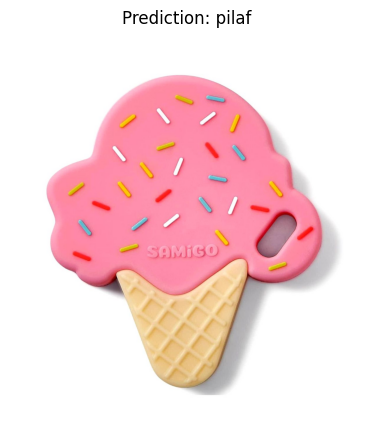

In [15]:

image = Image.open(filename).convert("RGB")

input_tensor = transform(image)
input_tensor = input_tensor.unsqueeze(0).to(device)

model.eval()

with torch.no_grad():

    outputs = model(input_tensor)

    probabilities = torch.softmax(
        outputs, dim=1
    )[0]

    confidence, predicted = torch.max(
        probabilities, dim=0
    )

predicted_class = CLASSES[predicted.item()]

print("Predicted Food:", predicted_class)
print(
    f"Confidence: {confidence.item() * 100:.2f}%"
)

plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.title(f"Prediction: {predicted_class}")
plt.axis("off")
plt.show()


In [16]:

for i, class_name in enumerate(CLASSES):

    print(
        f"{class_name}: "
        f"{probabilities[i].item() * 100:.2f}%"
    )


cheesecake: 24.80%
pizza: 1.75%
pilaf: 63.37%
kebab: 0.94%
chocolate_cake: 2.35%
hot_dog: 6.79%
